# Phase II: Proof of Concept (DS 3000)
## Do Options Price Earnings Moves Correctly?
#### Group Members: Aru Mehta, Joshua Lin, Calvin Liang, Chenjia Xiu

## 1. Central Motivation

When a company reports quarterly earnings, its stock often makes its biggest move of the quarter. Options let investors bet on that move. The most common earnings bet is a "straddle": buying a call (pays off if the stock rises) and a put (pays off if it falls). Because a straddle profits from a big move in either direction, its price is the market's forecast of how big the move will be. If a 100 dollar stock's straddle costs 6 dollars, the market expects roughly a ±6% move. This is called the "implied move".

Is that forecast right? Evidence is mixed. Home Depot's straddle overestimated its earnings moves by about 0.9 percentage points on average over 12 quarters [2], while Netflix's actual moves averaged about 11.9% against an implied 8.8% [3]. Research also suggests option prices around earnings are not fully efficient: straddles tend to do better when a stock's past earnings moves are large compared with its implied move [1].

**Question 1:** On average, do options overprice or underprice earnings moves, and how often does the actual move exceed the implied move?

**Question 2:** Using information available before the report (sector, past earnings moves, past earnings surprises, implied volatility), can we predict when the actual move will exceed the implied move?

For our project, given the large universe of potential stocks, we are going to mainly focus on the largest 25 technology stocks that trade in the United States.

**Sources**
1. Milian, J. A. (2023). "The Efficiency of Weekly Option Prices around Earnings Announcements." *Journal of Risk and Financial Management*, 16(5), 270. https://ideas.repec.org/a/gam/jjrfmx/v16y2023i5p270-d1145938.html
2. Market Chameleon via IBKR Campus (2024). "Home Depot's Earnings: A Look at Historical Straddle Performance." https://www.interactivebrokers.com/campus/traders-insight/securities/options/home-depots-earnings-a-look-at-historical-straddle-performance/
3. Market Chameleon via IBKR Campus (2024). "A Historical Visualization: NFLX Implied Earnings Moves vs Actual." https://www.interactivebrokers.com/campus/?p=201650

## 2. Data

Our group decided to focus on the 25 largest US-listed technology stocks by market cap (semiconductors, software, internet, and hardware). Tech names report earnings with big, frequent moves and have very liquid options, so the implied move is easy to measure.

We utilize three sources, all collected in Python:

1. **Alpha Vantage**: all the earnings data.
    * `EARNINGS` gives each company's past earnings reports, with report date, reported vs. expected earnings per share (EPS), surprise %, and whether it reported before or after the market.
    * `EARNINGS_CALENDAR` gives the next report date for every stock in one call.
2. **CBOE Delayed Quotes API**: each company's current option chain, with strike, bid/ask price, implied volatility, and volume. This is where implied moves come from.
3. **CBOE daily price history** (same site): daily closing prices, used to measure how much each stock actually moved after each report. Alpha Vantage's free key only gives the last 100 days of prices, which isn't enough to cover 12 quarters of reports, so prices come from CBOE.

**API limits:** each free Alpha Vantage key allows 25 calls a day, and this needs 26 (25 tickers plus the calendar), so we use more than one key and the code switches to the next one when a key runs out. It also saves every response in a `data/` folder and skips anything already saved, so rerunning the notebook doesn't use up more calls.

#### Data Pipeline

1. Pull each company's historical earnings figures and upcoming report dates from Alpha Vantage.
2. Pull options quotes data from CBOE.
3. Clean and consolidate the data.
4. Merge earnings dates with spot prices to measure each stock's actual earnings move.
5. Merge upcoming reporting dates with options quotes to gauge each stock's implied move.
6. Save data to csv files for visualizations.

In [1]:
import io
import json
import os
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ALPHA Vantage keys 
API_KEYS = ["DH2TJXTZ0NB1YE4Z", "4C44SR46OZR5P5EZ", "L8KGHLNZX7GS6HNN"]

# One color + one marker shape per subsector
COLORS = {"Semiconductors": "#2a78d6", "Software": "#eb6834",
          "Internet": "#1baf7a", "Hardware & Networking": "#eda100"}
MARKERS = {"Semiconductors": "o", "Software": "s", "Internet": "^", "Hardware & Networking": "D"}

os.makedirs("data", exist_ok=True)
HEADERS = {"User-Agent": "Mozilla/5.0"}
key_index = 0  


def alpha_vantage(params, as_text=False):
    """Calls Alpha Vantage, switching to the next key if the current one is out of calls.
    Returns None if every key is used up for today."""
    global key_index
    while key_index < len(API_KEYS):
        r = requests.get("https://www.alphavantage.co/query",
                         params={**params, "apikey": API_KEYS[key_index]}, timeout=30)
        time.sleep(12)   # free tier allows only a few calls per minute
        limited = ("Information" in r.text or "Note" in r.text) and len(r.text) < 500
        if not limited:
            return r.text if as_text else r.json()
        print(f"Key {key_index + 1} is out of calls for today, switching keys")
        key_index += 1
    return None


# 25 largest US-listed tech stocks by market cap (Nov 2026)
# The last few spots change frequently, so we can swap names if they move
SUBSECTOR = {
    "NVDA": "Semiconductors",  "AAPL": "Hardware & Networking", "GOOGL": "Internet",
    "MSFT": "Software",        "TSM": "Semiconductors",         "AVGO": "Semiconductors",
    "META": "Internet",        "MU": "Semiconductors",          "AMD": "Semiconductors",
    "ORCL": "Software",        "ASML": "Semiconductors",        "PLTR": "Software",
    "NFLX": "Internet",        "CSCO": "Hardware & Networking", "LRCX": "Semiconductors",
    "AMAT": "Semiconductors",  "IBM": "Software",               "INTC": "Semiconductors",
    "KLAC": "Semiconductors",  "QCOM": "Semiconductors",        "TXN": "Semiconductors",
    "ANET": "Hardware & Networking", "CRM": "Software",         "APP": "Software",
    "SHOP": "Internet",
}
TICKERS = list(SUBSECTOR)
print(len(TICKERS), "tickers")


25 tickers


### 2.1 Earnings history (Alpha Vantage)

In [2]:
def get_earnings(ticker):
    """Earnings history for one ticker. Saved to data/ so each ticker only uses one API call ever."""
    path = f"data/earnings_{ticker}.json"
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    data = alpha_vantage({"function": "EARNINGS", "symbol": ticker})
    if data is None or "quarterlyEarnings" not in data:
        print(f"{ticker}: no data yet -> {str(data)[:120]}")
        return None
    with open(path, "w") as f:
        json.dump(data, f)
    return data


frames = []
for t in TICKERS:
    data = get_earnings(t)
    if data is None:
        continue
    df = pd.DataFrame(data["quarterlyEarnings"])
    df["ticker"] = t
    frames.append(df)

earnings = pd.concat(frames, ignore_index=True)

# Clean up: numbers stored as text turned into numbers, keep the last 12 reports per company
earnings["reportedDate"] = pd.to_datetime(earnings["reportedDate"])
for col in ["reportedEPS", "estimatedEPS", "surprisePercentage"]:
    earnings[col] = pd.to_numeric(earnings[col], errors="coerce")
earnings = earnings[earnings["reportedDate"] <= pd.Timestamp.today()]
earnings = earnings.sort_values("reportedDate", ascending=False).groupby("ticker").head(12)
earnings = earnings[["ticker", "reportedDate", "reportTime", "reportedEPS",
                     "estimatedEPS", "surprisePercentage"]].reset_index(drop=True)
earnings["subsector"] = earnings["ticker"].map(SUBSECTOR)

missing = sorted(set(TICKERS) - set(earnings["ticker"]))
if missing:
    print("Still missing (rerun tomorrow):", missing)
earnings.to_csv("earnings.csv", index=False)
print(earnings.shape)
earnings.head(20)

Key 1 is out of calls for today, switching keys
Key 2 is out of calls for today, switching keys
Key 3 is out of calls for today, switching keys
SHOP: no data yet -> None
Still missing (rerun tomorrow): ['SHOP']
(288, 7)


,ticker,reportedDate,reportTime,reportedEPS,estimatedEPS,surprisePercentage,subsector
0,APP,2026-11-04,post-market,2.45,3.94,-37.8173,Software
1,QCOM,2026-11-04,post-market,2.56,1.46,75.3425,Semiconductors
2,ANET,2026-11-03,post-market,1.11,0.99,12.1212,Hardware & Networking
3,AMD,2026-11-03,post-market,1.84,1.68,9.5238,Semiconductors
4,PLTR,2026-11-02,post-market,0.32,0.32,0.0000,Software
5,AAPL,2026-11-02,post-market,2.05,1.98,3.5354,Hardware & Networking
6,INTC,2026-10-29,post-market,0.52,0.28,85.7143,Semiconductors
7,KLAC,2026-10-28,post-market,1.22,1.18,3.3898,Semiconductors
8,GOOGL,2026-10-28,post-market,2.12,2.94,-27.8912,Internet
9,MSFT,2026-10-28,post-market,4.89,4.71,3.8217,Software


### 2.2 Option chains (Cboe)

In [3]:
frames = []
for t in TICKERS:
    url = f"https://cdn.cboe.com/api/global/delayed_quotes/options/{t}.json"
    try:
        data = requests.get(url, headers=HEADERS, timeout=30).json()["data"]
    except Exception as e:
        print(f"{t}: option chain failed ({e})")
        continue
    df = pd.DataFrame(data["options"])
    df["ticker"] = t
    df["stock_price"] = data["current_price"]
    frames.append(df)
    time.sleep(0.5)

options = pd.concat(frames, ignore_index=True)

# Each contract symbol encodes expiry, call/put and strike
# Ex) AAPL261016C00250000, means the Apple (AAPL) October 16, 2026 Call option with strike price of $250.000
options["expiration"] = pd.to_datetime(options["option"].str[-15:-9], format="%y%m%d")
options["type"] = options["option"].str[-9].map({"C": "call", "P": "put"})
options["strike"] = options["option"].str[-8:].astype(int) / 1000
options = options[["ticker", "expiration", "type", "strike", "bid", "ask",
                   "iv", "volume", "open_interest", "stock_price"]]

options.to_csv("options.csv", index=False)
print(options.shape)
options.head()

(86142, 10)


,ticker,expiration,type,strike,bid,ask,iv,volume,open_interest,stock_price
0,NVDA,2026-11-13,call,185.0,0.51,0.55,0.0843,0.0,0.0,184.91
1,NVDA,2026-11-13,put,185.0,0.44,0.49,0.0866,0.0,0.0,184.91
2,NVDA,2026-11-13,call,190.0,0.39,0.43,1.3623,0.0,0.0,184.91
3,NVDA,2026-11-13,put,190.0,0.57,0.61,1.2419,0.0,0.0,184.91
4,NVDA,2026-11-13,call,195.0,0.27,0.31,0.6885,0.0,0.0,184.91


### 2.3 Example: the implied move today

For each stock: take the nearest expiration, find the strike closest to the stock price (ATM Strike), and add the call and put prices (midpoint of bid and ask). 

Implied move = straddle price / stock price.

In [4]:
options["mid"] = (options["bid"] + options["ask"]) / 2
future = options[options["expiration"] > pd.Timestamp.today()]
nearest = future[future["expiration"] == future.groupby("ticker")["expiration"].transform("min")].copy()
nearest["distance"] = (nearest["strike"] - nearest["stock_price"]).abs()
atm = nearest[nearest["distance"] == nearest.groupby("ticker")["distance"].transform("min")]
atm = atm[atm["strike"] == atm.groupby("ticker")["strike"].transform("min")]   # if two strikes tie, keep one

implied = atm.groupby("ticker").agg(stock_price=("stock_price", "first"),
                                    straddle=("mid", "sum"),
                                    expiration=("expiration", "first"))
implied["implied_move_%"] = (implied["straddle"] / implied["stock_price"] * 100).round(2)
implied

,stock_price,straddle,expiration,implied_move_%
ticker,,,,
AAPL,345.8100,6.340,2026-11-06,1.83
AMAT,330.3150,17.250,2026-11-06,5.22
AMD,421.7800,24.700,2026-11-06,5.86
ANET,160.6100,7.650,2026-11-06,4.76
APP,354.5000,18.150,2026-11-06,5.12
ASML,1395.0601,50.650,2026-11-06,3.63
AVGO,300.0922,12.175,2026-11-06,4.06
CRM,221.0600,6.455,2026-11-06,2.92
CSCO,96.9400,2.915,2026-11-06,3.01


### 2.4 Actual earnings moves (Cboe price history)

For each past report we measure the stock's move across the report:

* **Before the open** (pre-market): close the day before -> close on the report day.
* **After the close** (post-market): close on the report day -> close the next day.

We also save the stock's normal daily move (median absolute daily % change over the 20 trading days before the report) so earnings days can be compared with ordinary days, and the stock's average move in its earlier reports, which is known before each report and will be a model feature. This allows us to gauge whether or not an earnings move is more or less than its historical move.

In [5]:
def get_prices(ticker):
    """Daily closing prices from CBOE. Saved to data/ and refreshed every 12 hours."""
    path = f"data/prices_{ticker}.csv"
    if os.path.exists(path) and time.time() - os.path.getmtime(path) < 12 * 3600:
        return pd.read_csv(path, index_col=0, parse_dates=True)["close"]
    url = f"https://cdn.cboe.com/api/global/delayed_quotes/charts/historical/{ticker}.json"
    rows = requests.get(url, headers=HEADERS, timeout=30).json()["data"]
    px = pd.DataFrame(rows)
    px = pd.Series(pd.to_numeric(px["close"], errors="coerce").values,
                   index=pd.to_datetime(px["date"]), name="close")
    px = px.dropna().sort_index()
    px.to_frame().to_csv(path)
    return px


def earnings_move(px, report_date, report_time):
    """Signed % move across one report, plus the stock's normal daily move before it."""
    dates = px.index
    i = dates.searchsorted(report_date)            
    if report_time == "post-market":
        before_i = i if (i < len(dates) and dates[i] == report_date) else i - 1
        after_i = before_i + 1
    else:                                         
        before_i, after_i = i - 1, i
    if before_i < 21 or after_i >= len(dates):
        return np.nan, np.nan
    move = (px.iloc[after_i] / px.iloc[before_i] - 1) * 100
    normal = px.iloc[before_i - 20: before_i + 1].pct_change().abs().median() * 100
    return move, normal


prices = {t: get_prices(t) for t in earnings["ticker"].unique()}

moves = earnings.copy()
out = [earnings_move(prices[r.ticker], r.reportedDate, r.reportTime) for r in moves.itertuples()]
moves["move_%"] = [m for m, _ in out]
moves["normal_day_%"] = [n for _, n in out]
moves["abs_move_%"] = moves["move_%"].abs()

# Average size of the stock's EARLIER earnings moves (only uses info known before each report)
moves = moves.sort_values(["ticker", "reportedDate"])
moves["past_avg_abs_move_%"] = (moves.groupby("ticker")["abs_move_%"]
                                .transform(lambda s: s.shift(1).expanding().mean()))
moves = moves.reset_index(drop=True)

moves.to_csv("moves.csv", index=False)
print(moves.shape)
moves[["ticker", "reportedDate", "reportTime", "surprisePercentage",
       "move_%", "normal_day_%", "past_avg_abs_move_%"]].tail()

(288, 11)


,ticker,reportedDate,reportTime,surprisePercentage,move_%,normal_day_%,past_avg_abs_move_%
283,TXN,2025-10-21,post-market,5.3691,-5.601637,1.196428,5.646543
284,TXN,2026-01-27,post-market,-3.0534,9.937446,1.069474,5.640930
285,TXN,2026-04-22,post-market,22.6277,19.432102,1.473911,6.118321
286,TXN,2026-07-22,post-market,12.0419,-3.127231,2.432581,7.449699
287,TXN,2026-10-21,post-market,9.1667,-1.809239,0.756358,7.056747


### 2.5 Implied move for each stock's next report

The section 2.3 example uses the nearest expiration, which usually doesn't cover an earnings report. Here we use the Alpha Vantage earnings calendar to find each stock's next report and price the straddle for the **first expiration after that report**, so the option price actually includes the earnings move. We only keep reports in the next 45 days, because longer straddles mostly price ordinary days. Even so, this number includes a few normal days too, so it slightly overstates the pure earnings move.

In [6]:
def get_calendar():
    """Upcoming earnings dates for every US stock (one API call, saved for the day)."""
    path = "data/earnings_calendar.csv"
    if os.path.exists(path) and time.time() - os.path.getmtime(path) < 24 * 3600:
        cal = pd.read_csv(path)
        cal["reportDate"] = pd.to_datetime(cal["reportDate"], errors="coerce")
        return cal
    text = alpha_vantage({"function": "EARNINGS_CALENDAR", "horizon": "3month"}, as_text=True)
    if text is None or not text.startswith("symbol"):
        print("Calendar not available yet:", str(text)[:120])
        return None
    cal = pd.read_csv(io.StringIO(text))
    cal.to_csv(path, index=False)
    # Checks the dates are real dates (any odd value becomes NaT instead of breaking the comparison)
    cal["reportDate"] = pd.to_datetime(cal["reportDate"], errors="coerce")
    return cal


def straddle_move(chain, expiry):
    """ATM straddle price / stock price (%) for one expiration of one ticker's chain."""
    c = chain[chain["expiration"] == expiry].copy()
    if c.empty:
        return np.nan
    price = c["stock_price"].iloc[0]
    strike = c.loc[(c["strike"] - price).abs().idxmin(), "strike"]
    atm = c[c["strike"] == strike]
    if set(atm["type"]) != {"call", "put"}:
        return np.nan
    return atm["mid"].sum() / price * 100


today = pd.Timestamp.today().normalize()
cal = get_calendar()
rows = []
if cal is not None:
    nxt = cal[cal["symbol"].isin(TICKERS) & (cal["reportDate"] >= today)]
    nxt = nxt.sort_values("reportDate").groupby("symbol").head(1)
    for r in nxt.itertuples():
        chain = options[options["ticker"] == r.symbol]
        later = chain.loc[chain["expiration"] > r.reportDate, "expiration"]
        if later.empty:
            continue
        expiry = later.min()
        rows.append({"ticker": r.symbol, "next_report": r.reportDate, "expiration": expiry,
                     "days_to_report": (r.reportDate - today).days,
                     "implied_move_%": round(straddle_move(chain, expiry), 2)})

upcoming = pd.DataFrame(rows, columns=["ticker", "next_report", "expiration",
                                       "days_to_report", "implied_move_%"])
upcoming = upcoming[upcoming["days_to_report"] <= 45].sort_values("next_report")
upcoming.to_csv("upcoming_implied.csv", index=False)
upcoming

Calendar not available yet: None


,ticker,next_report,expiration,days_to_report,implied_move_%


## 3. How the data will be used

Each row of the final dataset will be one earnings report, with the implied move (from the option chain the day before the report), the actual move (the stock's price change across the report, from section 2.4), and features known before the report: subsector, report time (before or after market), past EPS surprises, the stock's average move in previous earnings reports, its normal daily move, and implied volatility. We will save option-chain snapshots before each report during the October–November earnings season.

For **Question 1**, we will compare actual and implied moves directly: the average difference and how often the actual move is bigger, overall and by subsector.

For **Question 2**, we will use classification (e.g. logistic regression or a decision tree) to predict whether the actual move will exceed the implied move, and regression to predict the ratio of the actual move to the implied move. We will then check whether these models beat the simple assumption that the options market is always right, and which features matter most.

Following this next earnings cycle, we can use our historical analysis to compare implied and actual moves for the reports that surface.

## 4. Visualizations

### 4.1 How big are earnings moves for each stock?

Each row is one stock. Every colored dot is one of its last 12 earnings reports, the shaded band covers the middle half of those moves, and the black tick is the median. The gray **×** is the stock's normal daily move, so the gap between the × and the dots shows how much bigger earnings days are than regular days. The hollow diamond is what the options market is pricing for the **next** report (section 2.5), where one is coming up soon.

This answers the setup for Question 1: if the diamond sits well to the left of where the dots usually land, options look cheap for that stock; if it sits far to the right, they look expensive. It also shows which stocks are the most and least predictable (tight vs. spread out dots), which matters for Question 2.

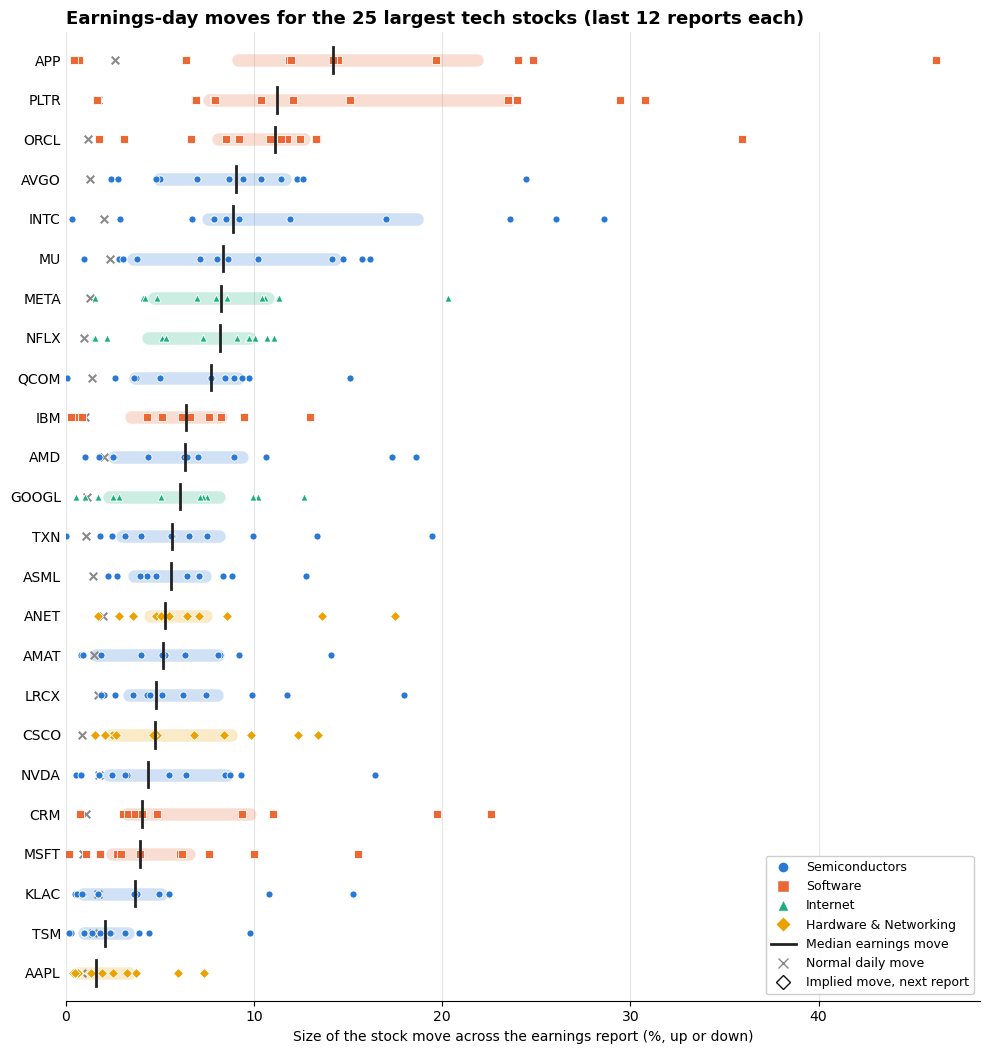

On a typical report, the earnings move is 4.1x the stock's normal daily move.


In [7]:
order = moves.groupby("ticker")["abs_move_%"].median().sort_values().index   # biggest movers at top
implied_next = upcoming.set_index("ticker")["implied_move_%"]

fig, ax = plt.subplots(figsize=(10, 0.36 * len(order) + 2))
for y, t in enumerate(order):
    d = moves.loc[moves["ticker"] == t, "abs_move_%"].dropna()
    color = COLORS[SUBSECTOR[t]]
    q1, med, q3 = d.quantile([0.25, 0.5, 0.75])
    ax.plot([q1, q3], [y, y], color=color, alpha=0.22, lw=9, solid_capstyle="round", zorder=1)
    ax.scatter(d, [y] * len(d), color=color, marker=MARKERS[SUBSECTOR[t]], s=26,
               edgecolor="white", linewidth=0.6, zorder=3)
    ax.plot([med, med], [y - 0.32, y + 0.32], color="#222222", lw=2, zorder=4)
    normal = moves.loc[moves["ticker"] == t, "normal_day_%"].median()
    ax.scatter(normal, y, marker="x", color="#8a8a8a", s=30, lw=1.5, zorder=2)
    if t in implied_next.index and pd.notna(implied_next[t]):
        ax.scatter(implied_next[t], y, marker="D", s=70, facecolor="none",
                   edgecolor="#111111", lw=1.6, zorder=5)

ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_ylim(-0.7, len(order) - 0.3)
ax.set_xlim(left=0)
ax.set_xlabel("Size of the stock move across the earnings report (%, up or down)")
ax.grid(axis="x", color="#e6e6e6", lw=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Earnings-day moves for the 25 largest tech stocks (last 12 reports each)",
             loc="left", fontsize=13, fontweight="bold")

handles = [Line2D([], [], marker=MARKERS[k], color="w", markerfacecolor=v, markersize=8, label=k)
           for k, v in COLORS.items()]
handles += [Line2D([], [], color="#222222", lw=2, label="Median earnings move"),
            Line2D([], [], marker="x", color="#8a8a8a", lw=0, markersize=7, label="Normal daily move"),
            Line2D([], [], marker="D", color="#111111", markerfacecolor="none", lw=0, markersize=7,
                   label="Implied move, next report")]
ax.legend(handles=handles, loc="lower right", frameon=True, framealpha=0.95, fontsize=9)
plt.tight_layout()
plt.show()

ratio = (moves["abs_move_%"] / moves["normal_day_%"]).median()
print(f"On a typical report, the earnings move is {ratio:.1f}x the stock's normal daily move.")

### 4.2 Do earnings surprises explain the move?

Each dot is one report: how much the company beat or missed the EPS estimate (x) against how much the stock moved (y). If surprises drove everything, the dots would hug the trend line. The four corners count how often a beat led to a rise, a beat led to a drop, and so on.

This matters for Question 2 because the surprise isn't known until after the report. If surprises barely explain the move, then predicting the size of the move has to come from other things known beforehand, like the stock's past moves, and it also tells us that direction is close to a coin flip (which is why a straddle, which doesn't care about direction, is the right trade to study). Surprises are capped at ±30% so a few extreme quarters don't squash the rest of the chart.

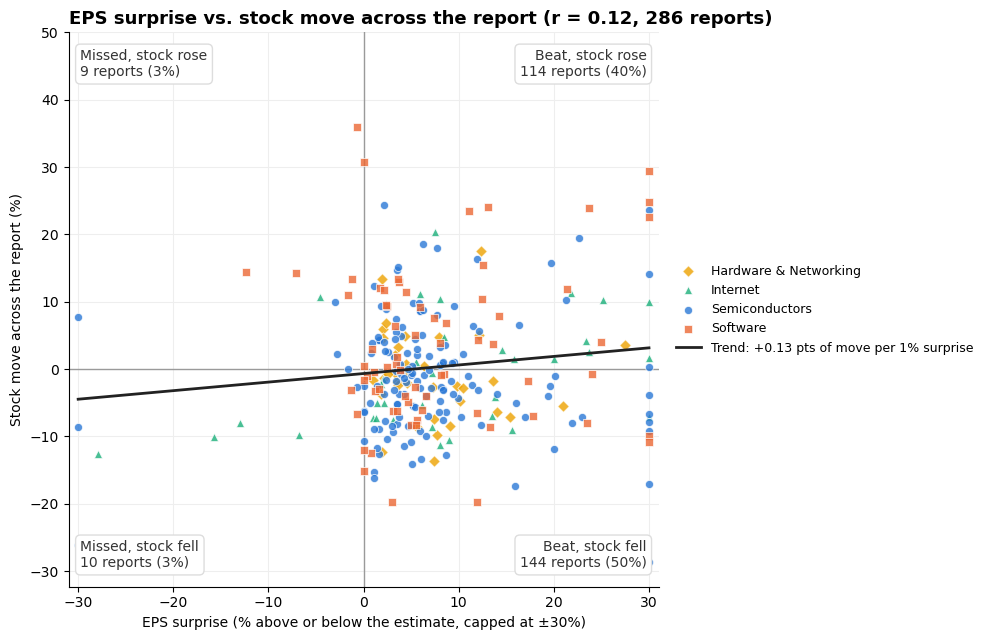

90% of reports beat the wall street estimate, but only 44% of those beats led to the stock going up.


In [8]:
d = moves.dropna(subset=["surprisePercentage", "move_%"]).copy()
d["surprise_capped"] = d["surprisePercentage"].clip(-30, 30)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axhline(0, color="#9a9a9a", lw=1, zorder=1)
ax.axvline(0, color="#9a9a9a", lw=1, zorder=1)
for sub, g in d.groupby("subsector"):
    ax.scatter(g["surprise_capped"], g["move_%"], color=COLORS[sub], marker=MARKERS[sub],
               s=34, alpha=0.8, edgecolor="white", linewidth=0.6, label=sub, zorder=3)

slope, intercept = np.polyfit(d["surprise_capped"], d["move_%"], 1)
xs = np.linspace(-30, 30, 50)
ax.plot(xs, intercept + slope * xs, color="#222222", lw=2, zorder=4,
        label=f"Trend: {slope:+.2f} pts of move per 1% surprise")
r = np.corrcoef(d["surprise_capped"], d["move_%"])[0, 1]

n = len(d)
corners = {
    "Beat, stock rose":   ((d["surprisePercentage"] > 0) & (d["move_%"] > 0), (0.98, 0.97), "right", "top"),
    "Beat, stock fell":   ((d["surprisePercentage"] > 0) & (d["move_%"] < 0), (0.98, 0.03), "right", "bottom"),
    "Missed, stock rose": ((d["surprisePercentage"] < 0) & (d["move_%"] > 0), (0.02, 0.97), "left", "top"),
    "Missed, stock fell": ((d["surprisePercentage"] < 0) & (d["move_%"] < 0), (0.02, 0.03), "left", "bottom"),
}
for label, (mask, (x, y), ha, va) in corners.items():
    ax.text(x, y, f"{label}\n{mask.sum()} reports ({mask.mean():.0%})", transform=ax.transAxes,
            ha=ha, va=va, fontsize=10, color="#333333",
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#dddddd"))

ax.set_xlim(-31, 31)
ax.set_xlabel("EPS surprise (% above or below the estimate, capped at ±30%)")
ax.set_ylabel("Stock move across the report (%)")
ax.set_title(f"EPS surprise vs. stock move across the report (r = {r:.2f}, {n} reports)",
             loc="left", fontsize=13, fontweight="bold")
ax.grid(color="#eeeeee", lw=0.8)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

beats = d["surprisePercentage"] > 0
print(f"{beats.mean():.0%} of reports beat the wall street estimate, but only "
      f"{(d.loc[beats, 'move_%'] > 0).mean():.0%} of those beats led to the stock going up.")

## 5. Functions for checking an ML model

We haven't picked the final models yet, but we know what questions we will need to ask about any model for Question 2. These functions answer them. Each one takes plain arrays (true values, predictions, dates or groups), so they work with any scikit-learn model we end up using.

| Function | What it checks | Why it matters here |
|---|---|---|
| `compare_to_baseline` | Error of the model vs. a simple baseline | The whole point of Question 2 is beating "the options market is always right" (actual/implied ratio = 1). A model that can't beat that is useless, even if its R² looks fine. |
| `classification_check` | Accuracy, precision, recall, ROC AUC and Brier score vs. always guessing the most common answer | If actual > implied happens, say, 40% of the time, a model that always says "no" is already 60% accurate. This shows whether the model adds anything beyond that. |
| `calibration_table` | Whether predicted probabilities match how often things really happen | A trade only makes sense if "70% chance the move beats the implied move" really happens about 70% of the time. Accuracy alone can't show this. |
| `walk_forward_check` | Train vs. test score when always training on the past and testing on the future | Earnings data is a time series. A normal random split lets the model peek at future quarters. A big train/test gap also means overfitting, which is a real risk with only ~300 reports. |
| `error_by_group` | Average error and bias for each subsector (or stock) | A model can look fine overall but always guess too high for semiconductors and too low for software. That bias would show up as losing trades in one group. |

In [9]:
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, brier_score_loss, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import TimeSeriesSplit


def compare_to_baseline(y_true, y_pred, y_baseline, model_name="Model", baseline_name="Baseline"):
    """Regression fit vs. a simple baseline.
    skill > 0 means the model beats the baseline (skill = 1 - model MSE / baseline MSE).
    For the final project, y_baseline = 1 (actual/implied ratio when options are priced right)."""
    y_true = np.asarray(y_true, dtype=float)
    y_baseline = np.broadcast_to(np.asarray(y_baseline, dtype=float), y_true.shape)
    rows = {}
    for name, pred in [(model_name, np.asarray(y_pred, dtype=float)), (baseline_name, y_baseline)]:
        rows[name] = {"MAE": mean_absolute_error(y_true, pred),
                      "RMSE": mean_squared_error(y_true, pred) ** 0.5,
                      "R2": r2_score(y_true, pred)}
    out = pd.DataFrame(rows).T
    out["skill_vs_baseline"] = 1 - out["RMSE"] ** 2 / out.loc[baseline_name, "RMSE"] ** 2
    return out.round(3)


def classification_check(y_true, y_prob, threshold=0.5):
    """Classification scores for the model vs. always predicting the most common class.
    y_prob = predicted probability that the actual move beats the implied move."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_hat = (y_prob >= threshold).astype(int)
    base_rate = y_true.mean()
    majority = np.full_like(y_true, int(base_rate >= 0.5))
    out = pd.DataFrame({
        "Model": [accuracy_score(y_true, y_hat),
                  precision_score(y_true, y_hat, zero_division=0),
                  recall_score(y_true, y_hat, zero_division=0),
                  roc_auc_score(y_true, y_prob),
                  brier_score_loss(y_true, y_prob)],
        "Always guess majority": [accuracy_score(y_true, majority),
                                  precision_score(y_true, majority, zero_division=0),
                                  recall_score(y_true, majority, zero_division=0),
                                  0.5,
                                  brier_score_loss(y_true, np.full(len(y_true), base_rate))],
    }, index=["accuracy", "precision", "recall", "ROC AUC", "Brier (lower is better)"])
    return out.round(3)


def calibration_table(y_true, y_prob, n_bins=5, plot=True):
    """Groups predictions into bins and compares the average predicted probability with
    how often the event actually happened."""
    df = pd.DataFrame({"y": np.asarray(y_true).astype(int), "p": np.asarray(y_prob, dtype=float)})
    df["bin"] = pd.qcut(df["p"], q=n_bins, duplicates="drop")
    table = df.groupby("bin", observed=True).agg(predicted=("p", "mean"), actual=("y", "mean"),
                                                 count=("y", "size"))
    if plot:
        fig, ax = plt.subplots(figsize=(4.5, 4.5))
        ax.plot([0, 1], [0, 1], color="#9a9a9a", lw=1, ls="--", label="Perfect calibration")
        ax.plot(table["predicted"], table["actual"], marker="o", color="#2a78d6", lw=2, label="Model")
        ax.set_xlabel("Predicted probability")
        ax.set_ylabel("Actual frequency")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_title("Calibration", loc="left", fontweight="bold")
        ax.legend(frameon=False, fontsize=9)
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)
        plt.tight_layout()
        plt.show()
    return table.round(3)


def walk_forward_check(model, X, y, dates, n_splits=4, scorer=mean_absolute_error):
    """Always trains on earlier reports and tests on later ones so there is no look ahead bias.
    Returns the train and test score for each fold. A test score much worse than the
    train score means the model is overfitting."""
    order = np.argsort(np.asarray(dates))
    X = np.asarray(X, dtype=float)[order]
    y = np.asarray(y, dtype=float)[order]
    d = pd.to_datetime(np.asarray(dates)[order])
    rows = []
    for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(X), start=1):
        m = clone(model).fit(X[tr], y[tr])
        rows.append({"fold": k, "train_until": d[tr].max().date(), "test_until": d[te].max().date(),
                     "n_train": len(tr), "n_test": len(te),
                     "train_score": scorer(y[tr], m.predict(X[tr])),
                     "test_score": scorer(y[te], m.predict(X[te]))})
    out = pd.DataFrame(rows)
    out["gap"] = out["test_score"] - out["train_score"]
    return out.round(3)


def error_by_group(y_true, y_pred, groups):
    """Average error and average absolute error for each group.
    Positive bias = the model guesses too low for that group (actual > predicted)."""
    df = pd.DataFrame({"group": np.asarray(groups),
                       "err": np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)})
    out = df.groupby("group").agg(n=("err", "size"), bias=("err", "mean"),
                                  MAE=("err", lambda e: e.abs().mean()))
    return out.sort_values("bias").round(3)

### 5.1 Trying the functions on a placeholder model

The implied move history is still being collected this earnings season, so we can't train the real models yet. To make sure the functions work, we test them on a stand-in problem that uses the data we already have: predicting the **size** of each earnings move using only things known beforehand (the stock's average past earnings move and its normal daily move).

* Regression: linear regression vs. the naive guess "this report will move the same as the stock's past average".
* Classification: will this move be **bigger than the stock's past average**? (A stand-in for "bigger than the implied move".)

Once the implied moves are in, the target becomes actual/implied and the baseline becomes 1.

In [10]:
from sklearn.linear_model import LinearRegression, LogisticRegression

demo = moves.dropna(subset=["abs_move_%", "past_avg_abs_move_%", "normal_day_%"])
demo = demo.sort_values("reportedDate").reset_index(drop=True)
features = ["past_avg_abs_move_%", "normal_day_%"]
X, y = demo[features].values, demo["abs_move_%"].values

# Train on the earliest 75% of reports, test on the latest 25%
cut = int(len(demo) * 0.75)
train, test = demo.iloc[:cut], demo.iloc[cut:]

reg = LinearRegression().fit(train[features], train["abs_move_%"])
reg_pred = reg.predict(test[features])
print("Regression vs. naive 'same as past average' guess:")
display(compare_to_baseline(test["abs_move_%"], reg_pred, test["past_avg_abs_move_%"],
                            "Linear regression", "Past average"))

print("Walk-forward check (MAE in % points, lower is better):")
display(walk_forward_check(LinearRegression(), X, y, demo["reportedDate"], n_splits=4))

print("Errors by subsector (test set):")
display(error_by_group(test["abs_move_%"], reg_pred, test["subsector"]))

Regression vs. naive 'same as past average' guess:


,MAE,RMSE,R2,skill_vs_baseline
Linear regression,5.128,6.814,-0.024,0.119
Past average,5.615,7.260,-0.163,0.000


Walk-forward check (MAE in % points, lower is better):


,fold,train_until,test_until,n_train,n_test,train_score,test_score,gap
0,1,2024-09-09,2025-04-23,54,52,3.787,4.497,0.711
1,2,2025-04-23,2025-10-29,106,52,4.276,4.063,-0.213
2,3,2025-10-29,2026-04-29,158,52,4.076,4.139,0.063
3,4,2026-04-29,2026-11-03,210,52,4.098,5.374,1.276


Errors by subsector (test set):


,n,bias,MAE
group,,,
Software,16,-1.234,7.097
Semiconductors,33,1.248,5.345
Hardware & Networking,8,1.496,3.581
Internet,9,1.750,2.208


Will the move be bigger than the stock's past average?


,Model,Always guess majority
accuracy,0.712,0.576
precision,0.714,0.000
recall,0.536,0.000
ROC AUC,0.705,0.500
Brier (lower is better),0.218,0.244


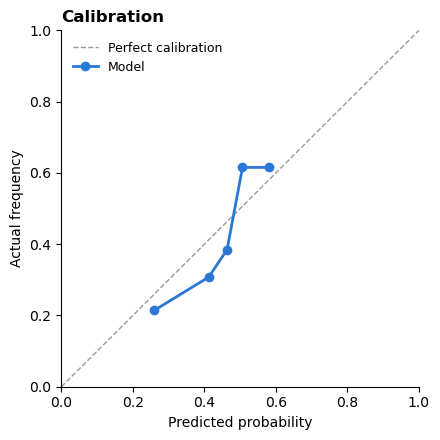

,predicted,actual,count
bin,,,
"(0.147, 0.346]",0.260,0.214,14
"(0.346, 0.441]",0.412,0.308,13
"(0.441, 0.484]",0.463,0.385,13
"(0.484, 0.534]",0.507,0.615,13
"(0.534, 0.653]",0.580,0.615,13


In [11]:
label = (demo["abs_move_%"] > demo["past_avg_abs_move_%"]).astype(int)
clf = LogisticRegression().fit(train[features], label.iloc[:cut])
prob = clf.predict_proba(test[features])[:, 1]

print("Will the move be bigger than the stock's past average?")
display(classification_check(label.iloc[cut:], prob))
calibration_table(label.iloc[cut:], prob, n_bins=5)

## 6. Ethical Implications of Data

Our research uses earnings data from Alpha Vantage, a provider of real-time and historical financial market data, and delayed options quotes and daily prices from the Chicago Board Options Exchange (CBOE) feed for the 25 largest technology stocks in the United States. Privacy risk is low for these data types, as no personal information is collected, but both sources have limits. Alpha Vantage’s free API key restricts usage to 25 requests a day, so we must keep requests to a minimum. Additionally, the largest technology firms are highly correlated with each other, so a volatile move in one can shift prices of others, especially around earnings. Therefore, our findings may not apply to companies with a smaller market capitalization or to other sectors.

Incorporating machine learning to this data can raise additional concerns. A model can falsely represent high accuracy if it is tested on the data it was trained on, or on data very similar to it, which is possible in this situation as these 25 stocks tend to move together. In particular, options are leveraged (magnify gains/losses) and volatile, especially as the contracts’ expiration date approaches. An incomplete model could cause major losses, particularly for retail investors who rely on the output too much. Conversely, institutional trading firms have access to faster data and proprietary models, so this research’s conclusions should not be used as a trading advantage of any sort. Therefore, we aim to treat this project as an educational analysis of how options prices behave around market catalysts, and should not be taken as financial advice.